In [1]:
from models.model import *
from models.ner_models import *
from data_access.DataProvider import *
from textpreprocessing.TextPreprocessing import *

provider = DataProvider()
rows = provider.get_articles('SL',100)
n = len(rows)

corpus = [[row[0], row[1]] for row in rows[0:n]]

c:\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from pipelines import *
rp = ReportFactory()

rp.generate_similarity_report(corpus,'SL','est.xlsx')

KeyboardInterrupt: 

In [6]:
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize

def plot_word_frequency(text):

    tokens = word_tokenize(text)
    text_list = Counter(tokens)

    unique_words = list(text_list.keys())
    frequencies = list(text_list.values())

    sorted_indices = sorted(range(len(frequencies)), key=lambda k: frequencies[k], reverse=True)
    sorted_indices = sorted_indices[:10]
    unique_words = [unique_words[i] for i in sorted_indices]
    frequencies = [frequencies[i] for i in sorted_indices]

    # Plot the bar chart
    plt.figure(figsize=(10, 5))
    plt.bar(range(len(unique_words)), frequencies, tick_label=unique_words, color='skyblue')
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.title('Word Frequency Bar Plot')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Example usage:
from textpreprocessing import *

tp = PolishTextPreprocessor()

text = tp.preprocess_text(corpus[1][1])
text = ''.join(text)


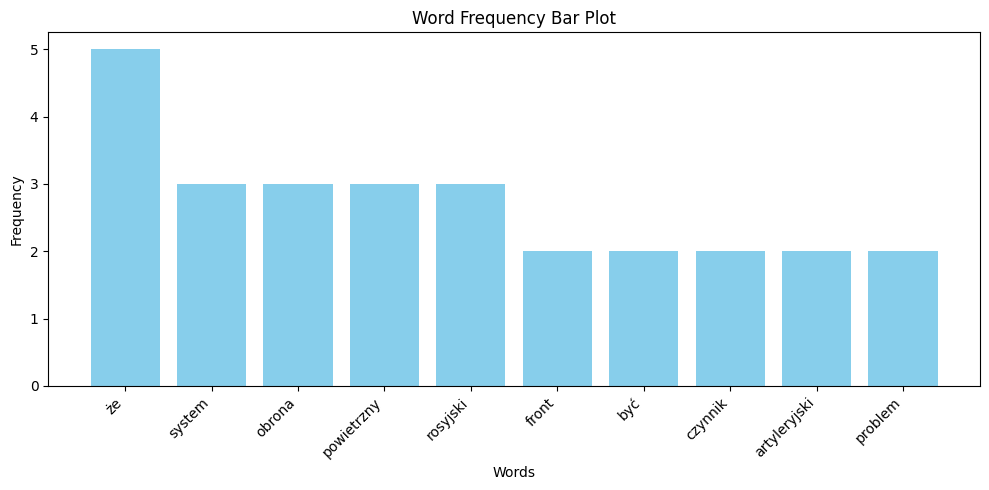

In [7]:
plot_word_frequency(text)

In [2]:
from data_access.DataProvider import *
from utils.utils import *
from models.model import EnglishBertModel

eb = EnglishBertModel()
db = DataInput()
rows = db.get_articles()

corpus = [row[2] for row in rows]

c:\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [61]:
import pandas as pd

# Replace 'your_file.xlsx' with the actual path to your Excel file
excel_file_path = 'PL_results.xlsx'

# Read the Excel file into a DataFrame with default column names (e.g., 0, 1, 2, ...)
df = pd.read_excel(excel_file_path, header=None)

# Access the vectors as Pandas Series
vector1 = df.iloc[:, 3]  # Access the first column
vector2 = df.iloc[:, 6]  # Access the second column

# Now, you can use vector1 and vector2 as your data
#print("Vector 1:", vector1)
#print("Vector 2:", vector2)

In [62]:
from scipy.stats import pearsonr
correlation_coefficient, p_value = pearsonr(vector1, vector2)

# Print the result
print("Pearson Correlation Coefficient:", correlation_coefficient)
print("P-value:", p_value)


Pearson Correlation Coefficient: 0.8435060562302235
P-value: 3.344646161866551e-28


In [64]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
array1 = np.array(vector1).reshape(1, -1)
array2 = np.array(vector2).reshape(1, -1)

# Calculate cosine similarity
cosine_similarity_value = cosine_similarity(array1, array2)

# Print the result
print("Cosine Similarity:", cosine_similarity_value[0][0])

Cosine Similarity: 0.8816722369343498


In [63]:
from scipy.stats import spearmanr

# Assuming vector1 and vector2 are the two vectors you obtained from Excel
# If you used the code from the previous responses, they would be Pandas Series

# Replace these vectors with your actual data
# Example with random data:

# Calculate Spearman rank correlation coefficient and p-value
spearman_coefficient, p_value = spearmanr(vector1, vector2)

# Print the result
print("Spearman Rank Correlation Coefficient:", spearman_coefficient)
print("P-value:", p_value)


Spearman Rank Correlation Coefficient: 0.8831227693604168
P-value: 5.569287093989259e-34
